# Muesli Project: Data Cleaning and EDA
Author: Daria Skibo

In this notebook I'm analysing the data received as an assignment for the Muesli Group project. The work mainly took place on March 13, than over the weeked, and was finished on March 16. The results of the EDA, performed in the group and individually, were presented on Monday.

**Structure of the Notebook**
1. Data Reading and DFs Overview<br>
    1.1 Orders<br>
    1.2. Interns<br>
    1.3. Process<br>
    1.4. Campaign<br> 
<br>

2. Data Cleaning and Merging<br>
    2.1. Orders<br>
    2.2. Interns, Process, Campaign<br>
    2.3. Merging<br>
<br>

3. Developing KPIs<br>
3.1. Creating KPIs<br>
    * processing time<br>
    * truck waiting / warehouse waiting<br>
    * full processing time (by warehouse and by truck company)<br>
    * transportation time (transit)<br>
    * total delivery time<br>
    <br>

    3.2. Creating "Day of Week" Columns<br>
    <br>

4. Data Distributions and Descriptive Statistics Overview<br>
    4.1. Structure of the Week<br>
    4.2. Orders Characteristics<br>
    4.3. Delivery Process Descriptive Stats<br>
<br>

5. KPIs: Calculation and Visualization by:<br>
    5.1. Shipment mode,<br>
    5.2. Region,<br>
    5.3. Number of items ordered,<br>
    5.4. Day of Ordering,<br>
    5.5. Origin,<br>
    Extra: Day of Ordering + Shipment Mode<br>

6. Conclusions and Recomendations<br>

For more information about the task, read `[assignment.md`. The original data file is `data.zip` (removed from the repo). Presentation of the group can be found in the `/presentation` folder.

## 1. Data Reading and Overview
The original data is represented in ```.xlsx``` format. The file consists of four parts, each includes information about a particular stage of the delivery process: 

1. **`Orders`**: basic information about each order (date, row_id, order_id, customer_name, region and other geographic data, shipment_mode, type of products ordered, amount, discount, sales, etc.).<br>
<br>

Problems: <br>
* **heavily duplicated**: each `order_id` is placed in the file multiple times, that doesn't provide a good overview about total amount of orders and could possibly skew the data distribution);
    * **solution**: remove duplicated orders; make `order_id` a column with unique values;
* **noise**: a lot of data that doesn't serve the purpose of the assignment (e.g., customer_name etc,);
    * **solution**: get rid of columns that are not part of meaningful metrics;
* **data formats mismatch**: some columns have data types, not matching the variable; e.g., `postal_code` has float format, date columns have string format;
    * **solution**: make data formats consistent and adequate to the variables.

2. **`InternData Study`**: information received from interns about the work of the warehouse; includes two most important metrics: `ready_to_ship_date` and `pickup_date`; matches the `Orders` tab by the `order_id` colum. <br>
<br>

Problems:<br>

* **heavily duplicated**: some `order_id`s represented multiple times;
    * **solution**: check for duplicates and drop them;
* **size**:  the data frame has relatively small size and can't be perceived as valid qithout additional checks;
    * **solution**: validation of the statistics by using other metrics (e.g., compating to the outcomes of the other tabs -> see below).
<br>

3. **`Order Process Data`**: information on this tab comes from the trucks' company; it matches the `Orders` tab by unique column `row_id`; it has two categories for the shipment mode (that differs from the shipment modes in the `Orders`dataset) and the date, when the order was actually picked up and scanned by a truck. <br>
<br>
Problems: <br>

* **partially duplicated**: has information about orders with the same `order_id` multiple times;
    * **solution**: remove the duplicates;
* **shipment mode inconsistency**: the shipment modes used by the Muesli compny (on the level of registering the order and processing it in the warehouse) do not match the shipment modes on the trucks' company;
    * **solution**: keep both, compare outcomes;
* **warehouse processing time duplicated**: using data from both `InternsData Study` and `Order Process Data` I can basically create the identical metric (aka warehouse processing time); probably, I don't need to metrics for the same process;
    * **solution**: use both metrics to validate them (e.g., if they are similar by distribution and main descriptive statistics, they are valid).
<br>

4. **`Campaign Data`**: information about the time when a client received an order.<br>
<br>
Problems:<br>

* **size**: relatively small dataset; incomplete;
    * **solution**: no solution; I'm going to use it the way it is;
* **reliability**: the assumption is that the clients scan the QRcode on the day they received their orders, but we can't check for it;
    * **solution**: no solution; use it the way it is.

Each dataframe is read from the `.xlsx` file separately, saved in a separated dataframe, and cleaned. You can see the basic information about columns, shape, and data types for each data frame below.

In [ ]:
# importing all the libraries needed for EDA and visuzlization

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'pandas'

### 1.1. Orders DataFrame

In [ ]:
df_orders = pd.read_excel('data_raw_copy.xlsx',sheet_name = 'Orders', header = 1)
df_orders.head(3)

,Index,Order ID,Order Date,Ship Mode,Customer ID,Customer Name,Origin Channel,Country/Region,City,State,Postal Code,Region,Category,Sub-Category,Product ID,Sales,Quantity,Discount,Profit
0,27,CA-2019-121755,2019-01-16,Second Class,EH-13945,Eric Hoffmann,Email,United States,Los Angeles,California,90049.0,West,Special Projects Muesil,Gluten Free,TEC-AC-10003027,90.57,3,0.0,11.7741
1,45,CA-2019-118255,2019-03-11,First Class,ON-18715,Odella Nelson,Sales,United States,Eagan,Minnesota,55122.0,Central,Special Projects Muesil,Gluten Free,TEC-AC-10000171,45.98,2,0.0,19.7714
2,48,CA-2019-169194,2019-06-20,Standard Class,LH-16900,Lena Hernandez,Email,United States,Dover,Delaware,19901.0,East,Special Projects Muesil,Gluten Free,TEC-AC-10002167,45.00,3,0.0,4.9500


In [ ]:
# save the file as .csv if needed:
# df_orders.to_csv('./data_csv/orders.csv',sep = ',', header = True, index = False)

In [ ]:
print('------------------ Orders Shape ------------------')
print(df_orders.shape)
print('------------------ Orders Structure and Null Values ------------------')
print(df_orders.info())
print('------------------ Orders Columns as a List ------------------')
print(df_orders.columns)

------------------ Orders Shape ------------------
(9994, 19)
------------------ Orders Structure and Null Values ------------------
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Index           9994 non-null   int64         
 1   Order ID        9994 non-null   str           
 2   Order Date      9994 non-null   datetime64[us]
 3   Ship Mode       9994 non-null   str           
 4   Customer ID     9994 non-null   str           
 5   Customer Name   9994 non-null   str           
 6   Origin Channel  9994 non-null   str           
 7   Country/Region  9994 non-null   str           
 8   City            9994 non-null   str           
 9   State           9994 non-null   str           
 10  Postal Code     9983 non-null   float64       
 11  Region          9994 non-null   str           
 12  Category        9994 non-null   str   

### 1.2. Interns DataFrame

In [ ]:
df_intern = pd.read_excel('data_raw_copy.xlsx',sheet_name = 'InternData Study', header = 0)
df_intern.head(2)

,Order ID,Ready to Ship Date,Pickup Date
0,CA-2019-116540,2019-09-02,2019-09-03
1,CA-2019-116540,2019-09-02,2019-09-03


In [ ]:
# save the file as .csv if needed:
# df_orders.to_csv('./data_csv/interns.csv',sep = ',', header = True, index = False)

In [ ]:
print('------------------ Interns Shape ------------------')
print(df_intern.shape)
print('------------------ Interns Structure and Null Values ------------------')
print(df_intern.info())
print('------------------ Interns Columns as a List ------------------')
print(df_intern.columns)

------------------ Interns Shape ------------------
(290, 3)
------------------ Interns Structure and Null Values ------------------
<class 'pandas.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Order ID            290 non-null    str           
 1   Ready to Ship Date  290 non-null    datetime64[us]
 2   Pickup Date         290 non-null    datetime64[us]
dtypes: datetime64[us](2), str(1)
memory usage: 6.9 KB
None
------------------ Interns Columns as a List ------------------
Index(['Order ID', 'Ready to Ship Date', 'Pickup Date'], dtype='str')


### 1.3. Process DataFrame

In [ ]:
df_process = pd.read_excel('data_raw_copy.xlsx',sheet_name = 'Order Process Data', header = 0)
df_process.head(3)

,Row ID,Order ID,Order Date,On Truck Scan Date,Ship Mode
0,1,CA-2019-152156,2019-11-08,2019-11-13,Standard Processing
1,2,CA-2019-152156,2019-11-08,2019-11-13,Standard Processing
2,3,CA-2019-138688,2019-06-12,2019-06-19,Standard Processing


In [ ]:
# save as a .csv file if needed:
# df_process.to_csv('./data_csv/process.csv',sep = ',', header = True, index = False)

In [ ]:
print('------------------ Process Shape ------------------')
print(df_process.shape)
print('------------------ Process Structure and Null Values ------------------')
print(df_process.info())
print('------------------ Process Columns as a List ------------------')
print(df_process.columns)

------------------ Process Shape ------------------
(5899, 5)
------------------ Process Structure and Null Values ------------------
<class 'pandas.DataFrame'>
RangeIndex: 5899 entries, 0 to 5898
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Row ID              5899 non-null   int64         
 1   Order ID            5899 non-null   str           
 2   Order Date          5899 non-null   datetime64[us]
 3   On Truck Scan Date  5899 non-null   datetime64[us]
 4   Ship Mode           5899 non-null   str           
dtypes: datetime64[us](2), int64(1), str(2)
memory usage: 230.6 KB
None
------------------ Process Columns as a List ------------------
Index(['Row ID', 'Order ID', 'Order Date', 'On Truck Scan Date', 'Ship Mode'], dtype='str')


### 1.4. Campaign DataFrame

In [ ]:
df_campaign = pd.read_excel('data_raw_copy.xlsx',sheet_name = 'Campaign Data', header = 0)
df_campaign.head(3)


,Order ID,Arrival Scan Date,Customer Name
0,CA-2019-109666,2019-05-03,Kunst Miller
1,CA-2019-138933,2019-05-03,Jack Lebron
2,CA-2019-130001,2019-05-03,Heather Kirkland


In [ ]:
# save the file as .csv if needed:
# df_campaign.to_csv('./data_csv/campaign.csv',sep = ',', header = True, index = False)

In [ ]:
print('------------------ Campaign Shape ------------------')
print(df_campaign.shape)
print('------------------ Campaign Structure and Null Values ------------------')
print(df_campaign.info())
print('------------------ Campaign Columns as a List ------------------')
print(df_campaign.columns)

------------------ Campaign Shape ------------------
(333, 3)
------------------ Campaign Structure and Null Values ------------------
<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order ID           333 non-null    str           
 1   Arrival Scan Date  333 non-null    datetime64[us]
 2   Customer Name      333 non-null    str           
dtypes: datetime64[us](1), str(2)
memory usage: 7.9 KB
None
------------------ Campaign Columns as a List ------------------
Index(['Order ID', 'Arrival Scan Date', 'Customer Name'], dtype='str')


## 2. Data Cleaning and Merging

### 2.1. Orders DataFrame Cleaning

In [14]:
df_orders.columns = df_orders.columns.str.lower()
df_orders.columns = df_orders.columns.str.replace(' ','_')
df_orders['total_items'] = df_orders.groupby("order_id")["quantity"].transform("sum")
df_orders = df_orders.drop(columns=['customer_id', 'customer_name','country/region', 
'city','state', 'postal_code','category', 'product_id', 'sales', 'discount','profit', 'sub-category', 'quantity'])
df_orders.rename(columns={"index": "row_id"}, inplace=True)

# save the clean version of orders as a .csv file if needed:
#df_orders.to_csv('../data_csv/orders_min.csv')

# preliminary result:
df_orders.head(2)
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   row_id          9994 non-null   int64         
 1   order_id        9994 non-null   str           
 2   order_date      9994 non-null   datetime64[us]
 3   ship_mode       9994 non-null   str           
 4   origin_channel  9994 non-null   str           
 5   region          9994 non-null   str           
 6   total_items     9994 non-null   int64         
dtypes: datetime64[us](1), int64(2), str(4)
memory usage: 546.7 KB


### 2.2. Interns, Process, and Campaign Cleaning

In [15]:
# Intrens:
df_intern.columns = df_intern.columns.str.lower()
df_intern.columns = df_intern.columns.str.replace(' ','_')

df_intern["ready_to_ship_date"] = pd.to_datetime(df_intern["ready_to_ship_date"])
df_intern["pickup_date"] = pd.to_datetime(df_intern["pickup_date"])

df_intern["order_id"].duplicated().sum()

df_intern = df_intern.drop_duplicates(subset="order_id", keep="first")

df_intern.info()

<class 'pandas.DataFrame'>
Index: 204 entries, 0 to 289
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            204 non-null    str           
 1   ready_to_ship_date  204 non-null    datetime64[us]
 2   pickup_date         204 non-null    datetime64[us]
dtypes: datetime64[us](2), str(1)
memory usage: 6.4 KB


In [16]:
df_process.shape

(5899, 5)

In [17]:
df_process.columns

Index(['Row ID', 'Order ID', 'Order Date', 'On Truck Scan Date', 'Ship Mode'], dtype='str')

In [18]:
# Process:
df_process.head(2)
df_process.columns = df_process.columns.str.lower()
df_process.columns = df_process.columns.str.replace(' ','_')

df_process["on_truck_scan_date"] = pd.to_datetime(df_process["on_truck_scan_date"])
df_process.rename(columns={"ship_mode": "truck_ship_mode"}, inplace=True)

df_process = df_process.drop_duplicates(subset="order_id", keep="first")

df_process = df_process.drop(columns=['order_id','order_date'])

df_process.info()

<class 'pandas.DataFrame'>
Index: 3002 entries, 0 to 5898
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   row_id              3002 non-null   int64         
 1   on_truck_scan_date  3002 non-null   datetime64[us]
 2   truck_ship_mode     3002 non-null   str           
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 93.8 KB


In [19]:
# Campaign:
df_campaign.head(2)

df_campaign.columns = df_campaign.columns.str.lower()
df_campaign.columns = df_campaign.columns.str.replace(' ','_')

df_campaign["arrival_scan_date"] = pd.to_datetime(df_campaign["arrival_scan_date"])

df_campaign = df_campaign.drop(columns = ['customer_name'])

df_campaing = df_campaign.drop_duplicates(subset="order_id", keep="first")

df_campaign.info()

<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   order_id           333 non-null    str           
 1   arrival_scan_date  333 non-null    datetime64[us]
dtypes: datetime64[us](1), str(1)
memory usage: 5.3 KB


In [20]:
print(f"As an output of cleaning stage, we have the following four dataframes: \nORDERS: n = {len(df_orders)}, \nINTERN: n = {len(df_intern)}, \nPROCESS: n= {len(df_process)}, \nCAMPAIGN: n = {len(df_campaign)}.")

As an output of cleaning stage, we have the following four dataframes: 
ORDERS: n = 9994, 
INTERN: n = 204, 
PROCESS: n= 3002, 
CAMPAIGN: n = 333.


### 2.3. DataFrames Merging
We first merge ```df_orders``` with ```df_process``` by the column ```row_id```; then we add information from interns dataframe and from campaign dataframe.

In [21]:
df_short = df_orders.merge(df_process, how='outer', on='row_id')
df_short.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   row_id              9994 non-null   int64         
 1   order_id            9994 non-null   str           
 2   order_date          9994 non-null   datetime64[us]
 3   ship_mode           9994 non-null   str           
 4   origin_channel      9994 non-null   str           
 5   region              9994 non-null   str           
 6   total_items         9994 non-null   int64         
 7   on_truck_scan_date  3002 non-null   datetime64[us]
 8   truck_ship_mode     3002 non-null   str           
dtypes: datetime64[us](2), int64(2), str(5)
memory usage: 702.8 KB


Since the data about all orders' pickups is preserved, we now can remove duplicated from the ```orders``` dataframe:

In [22]:
# how many duplicates do we have:
df_short[["order_id"]].duplicated().value_counts()

False    5009
True     4985
Name: count, dtype: int64

In [23]:
# now we can drop the duplicates and the column row_id, because we don't need it anymore:
df_unique = df_short.drop_duplicates(subset="order_id", keep="first")
df_unique = df_unique.drop(columns=['row_id'])
df_unique.info()

<class 'pandas.DataFrame'>
Index: 5009 entries, 0 to 9993
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            5009 non-null   str           
 1   order_date          5009 non-null   datetime64[us]
 2   ship_mode           5009 non-null   str           
 3   origin_channel      5009 non-null   str           
 4   region              5009 non-null   str           
 5   total_items         5009 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
dtypes: datetime64[us](2), int64(1), str(5)
memory usage: 352.2 KB


At this stage, we decreased the number of rows from ```9994``` to ```5009```, all with unique ```order_id```.
Now, we merge the existing data frame with information from ```df_intern```:

In [24]:
df_unique_add = df_unique.merge(df_intern,how = 'left', on='order_id')
df_unique_add.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            5009 non-null   str           
 1   order_date          5009 non-null   datetime64[us]
 2   ship_mode           5009 non-null   str           
 3   origin_channel      5009 non-null   str           
 4   region              5009 non-null   str           
 5   total_items         5009 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
 8   ready_to_ship_date  204 non-null    datetime64[us]
 9   pickup_date         204 non-null    datetime64[us]
dtypes: datetime64[us](4), int64(1), str(5)
memory usage: 391.5 KB


So, we have information about the warehouse important dates; total of ```204```valid entries.
Now, we add the last information from ```df_campaign```:

In [25]:
df_unique_all = df_unique_add.merge(df_campaign, how='left', on='order_id')
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            5009 non-null   str           
 1   order_date          5009 non-null   datetime64[us]
 2   ship_mode           5009 non-null   str           
 3   origin_channel      5009 non-null   str           
 4   region              5009 non-null   str           
 5   total_items         5009 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
 8   ready_to_ship_date  204 non-null    datetime64[us]
 9   pickup_date         204 non-null    datetime64[us]
 10  arrival_scan_date   333 non-null    datetime64[us]
dtypes: datetime64[us](5), int64(1), str(5)
memory usage: 430.6 KB


```df_unique_all``` dataframe consists of the dataset without duplicates, with all the important information merged together. This dataframe also has proper datatypes:

In [26]:
df_unique_all.dtypes

order_id                         str
order_date            datetime64[us]
ship_mode                        str
origin_channel                   str
region                           str
total_items                    int64
on_truck_scan_date    datetime64[us]
truck_ship_mode                  str
ready_to_ship_date    datetime64[us]
pickup_date           datetime64[us]
arrival_scan_date     datetime64[us]
dtype: object

In [27]:
# it can be also saved if needed:
# df_unique_all.to_csv('./data_csv/df_merged_all_dedub.csv',sep = ',', header = True, index = False)

## 3. Developing KPIs
Disclaimer: In this notebook I calculate all the KPIs in business days (**not** including Saturdays and Sundays). Why:
* from the assignment, it's not explicit, if we need to take into account that warehouse has days, when it's closed, and that the trucks company also doesn't pick up orders everyday; we also do not know, if transport company runs its trucks on the weekend (this part of delivery chain is missing in our data);
* since we have clear information about the warehouse working days + truck pickups days, I assumed that I can concentrate on running the business days statistics;
* I also ran the calendar days statistics at first, and this metrics were way more pessimistic;
* in our group presentation you can see both approaches preserved: Erick spoke mainly about calendar days distributions, and I spoke only about business days distributions.

In order to understand the problems of the Muesli Business, I developed the following KPIs: 

3.1. **Processing Time**: how much time does it take for order to be ready?
    * calculated: order date -------> ready to ship date;
    * based on data received from ```Interns```;
    * n = ```204```;

3.2.1. **Truck Waiting Days**: how much time does it take for the order to be picked up from the warehouse, when it's ready to be delivered?
    * calculated: ready to ship date ------> pickup date;
    * based on data received from ```Interns```;
    * n = 204;

3.2.2. **Warehouse Waiting Days**: ~identical to the 3.2. but calculated from a different data source;
    * calculated: ready to ship date ------> on truck scan date;
    * based on data received from ```Interns``` and ```Process```;
    * n = 204
    * why the second metric: to check validity;


3.3.1. **Warehouse Data: Full Processing Time**: how many business days pass from the moment od ordering until the pickup date?
    * calculated: order date ------> pickup date;
    * based on ```Interns``` data **fully**;
    * n = 204


3.3.2. **Truck Data: Full Processing Time**: how many business days pass from the prder to scan on truck date?
    * calculated: order date ------> scan on truck date;;
    * based on ```Process```data **fully**;
    * n = 3002


3.5. **Transport Days**: how many days an order spends in transit?
    * calculated: # on truck scan ------> arrival scan date;
    * based on ```Process``` and ```Campaign``` data;
    * n = 333

3.6. **Total Delivery Time**: how many business days passed from the moment of order registration until the arrival?
    * calculated: order date ------> arrival scan date;
    * based on ```Orders``` and ```Campaign````
    * n = 333




### 3.1. Creating All the KPIs

#### KPI 3.1 - PROCESSING DAYS

In [28]:
# processing_time
# calculated as:
# order date -------> ready to ship
mask = df_unique_all["order_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "process_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            5009 non-null   str           
 1   order_date          5009 non-null   datetime64[us]
 2   ship_mode           5009 non-null   str           
 3   origin_channel      5009 non-null   str           
 4   region              5009 non-null   str           
 5   total_items         5009 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
 8   ready_to_ship_date  204 non-null    datetime64[us]
 9   pickup_date         204 non-null    datetime64[us]
 10  arrival_scan_date   333 non-null    datetime64[us]
 11  process_days_biz    204 non-null    float64       
dtypes: datetime64[us](5), float64(1), int64(1), str(5)
memory usage: 469.7 KB


#### KP1 3.2.1 - TRUCK WAITING DAYS

In [29]:
# truck waiting days
# calculated as:
# ready to ship ------> pickup date
# according to interns
mask = df_unique_all["pickup_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "truck_wait_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "pickup_date"].values.astype("datetime64[D]")
)
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
dtypes: datetime64[us](5), float64(2), int64(1), 

#### KPI 3.2.2. - WAREHOUSE WAITING DAYS

In [30]:
# warehouse waiting days: pretty similar to truck waiting days; calculated from a different variable: 
# reday to ship ------> on truck scan
mask = df_unique_all["on_truck_scan_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "war_wait_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]")
)
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

#### KPI 3.3.1. - WAREHOUSE DATA: FULL PROCESSING TIME

In [31]:
# warehouse data, full processing time:
mask = df_unique_all["order_date"].notna() & df_unique_all["pickup_date"].notna()

df_unique_all.loc[mask, "warehouse_full"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "pickup_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

#### KPI 3.3.2. - TRUCK DATA: FULL PROCESSING TIME

In [32]:
# time between order creation and on_truck_scan_date:

mask = df_unique_all["order_date"].notna() & df_unique_all["on_truck_scan_date"].notna()

df_unique_all.loc[mask, "truck_data"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]")
)
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

#### KPI 3.4. - TRANSPORTATION DAYS

In [33]:
# transport days
# calculated as:
# on truck scan ------> arrival scan
mask = df_unique_all["arrival_scan_date"].notna() & df_unique_all["on_truck_scan_date"].notna()

df_unique_all.loc[mask, "transp_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

#### KPI 3.5. - TOTAL DELIVERY DAYS

In [34]:
# total delivery time
# calculated:
# order date ------> arrival scan

mask = df_unique_all["order_date"].notna() & df_unique_all["arrival_scan_date"].notna()

df_unique_all.loc[mask, "total_delivery_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   order_id                 5009 non-null   str           
 1   order_date               5009 non-null   datetime64[us]
 2   ship_mode                5009 non-null   str           
 3   origin_channel           5009 non-null   str           
 4   region                   5009 non-null   str           
 5   total_items              5009 non-null   int64         
 6   on_truck_scan_date       3002 non-null   datetime64[us]
 7   truck_ship_mode          3002 non-null   str           
 8   ready_to_ship_date       204 non-null    datetime64[us]
 9   pickup_date              204 non-null    datetime64[us]
 10  arrival_scan_date        333 non-null    datetime64[us]
 11  process_days_biz         204 non-null    float64       
 12  truck_wait_days_biz      204 non-null    floa

### 3.2. Creating Days of Week Columns
I will need it for the future work on distribution of each stage of delivery across the days of the week.

In [35]:
# order:
df_unique_all["order_weekday"]=df_unique_all["order_date"].dt.dayofweek
# became integer because there are no missing values

# ready to ship (warehouse):
df_unique_all["ready_ship_weekday"]=df_unique_all["ready_to_ship_date"].dt.dayofweek
# became float because there are missing values

# pickup date (interns):
df_unique_all["pickup_weekday"]=df_unique_all["pickup_date"].dt.dayofweek

# on truck scan (logistics company):
df_unique_all["on_truck_weekday"]=df_unique_all["on_truck_scan_date"].dt.dayofweek

# arrival scan (user):
df_unique_all["arrival_weekday"]=df_unique_all["arrival_scan_date"].dt.dayofweek

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   order_id                 5009 non-null   str           
 1   order_date               5009 non-null   datetime64[us]
 2   ship_mode                5009 non-null   str           
 3   origin_channel           5009 non-null   str           
 4   region                   5009 non-null   str           
 5   total_items              5009 non-null   int64         
 6   on_truck_scan_date       3002 non-null   datetime64[us]
 7   truck_ship_mode          3002 non-null   str           
 8   ready_to_ship_date       204 non-null    datetime64[us]
 9   pickup_date              204 non-null    datetime64[us]
 10  arrival_scan_date        333 non-null    datetime64[us]
 11  process_days_biz         204 non-null    float64       
 12  truck_wait_days_biz      204 non-null    floa

In [36]:
# can be saved if needed:
df_unique_all.to_csv('./data_csv/all_kpis.csv')

I don't need all the columns with dates, because they are already re-calculated to the metrics:


In [37]:
df_unique_all = df_unique_all.drop(columns=['order_date','on_truck_scan_date', 'ready_to_ship_date',
                                            'pickup_date', 'arrival_scan_date'])

## 4. Data Distributions
In this part I'm talking about the distribution of ordering, processing, preparing for pick up, picking up, delivering by days of the weeks. It will help us to understand the structure of the week and to think about probable "bottlenecks" during the KPIs analysis.

### 4.1. Structure of the week
* Orders distribution
* Warehouse workload
* Truck pickups / scan on truck
* Deliveries
* All stages of delivery process together

#### 4.1.1. Orders by Days of the Week

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/1081865953.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


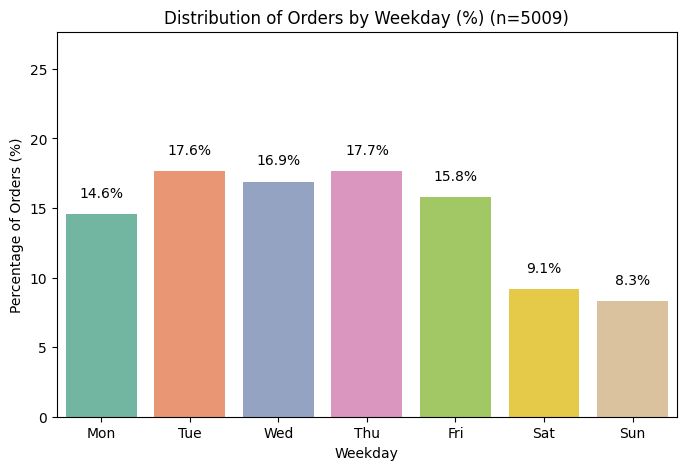

In [38]:
# sample size count:
n = df_unique_all["order_weekday"].dropna().shape[0]

# distribution + normalization:
weekday_counts = df_unique_all["order_weekday"].value_counts(normalize=True).sort_index()
weekday_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

# counting percentage:
weekday_percent = weekday_counts * 100

# plot: 
plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title(f"Distribution of Orders by Weekday (%) (n={n})")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


#### 4.1.2. Ready to Be Shipped by the Day of the Week

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/2071587189.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


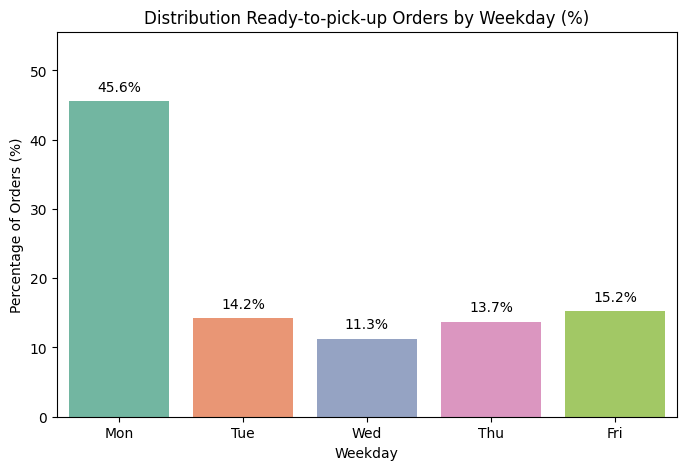

In [39]:
weekday_counts = df_unique_all["ready_ship_weekday"].value_counts(normalize=True).sort_index()
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"] # they don't work on Sat and Sun + I checked

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution Ready-to-pick-up Orders by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


#### 4.1.3 Distribution of Registered Pickups by the Day of the Week

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/4063026110.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


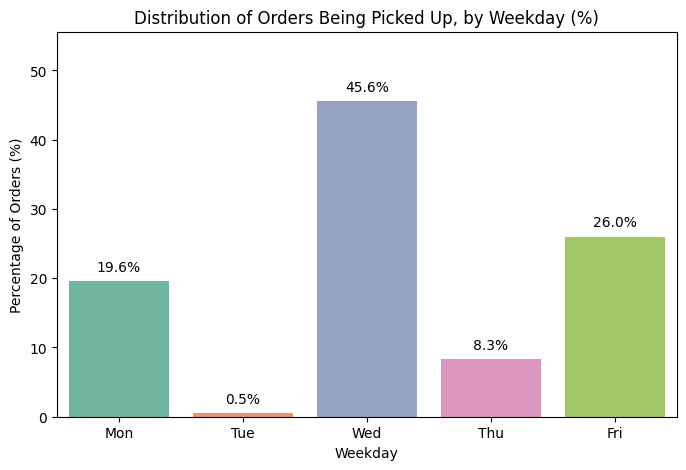

In [40]:
weekday_counts = df_unique_all["pickup_weekday"].value_counts(normalize=True).sort_index()
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Orders Being Picked Up, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


#### 4.1.4. Orders Picked Up by Trucks by the Day of the Week

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/1010804438.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


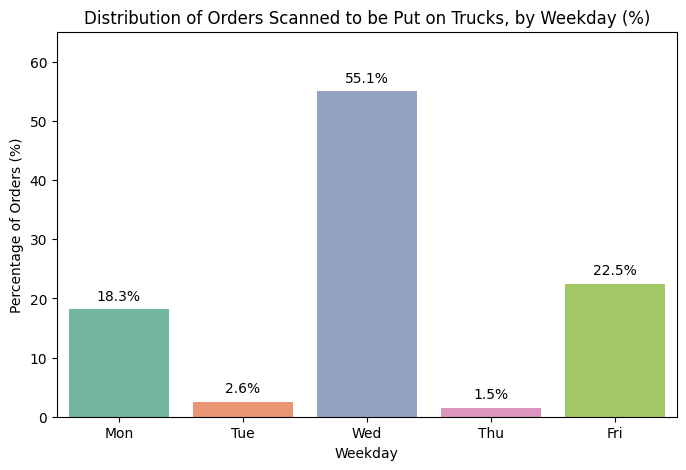

In [41]:
weekday_counts = df_unique_all["on_truck_weekday"].value_counts(normalize=True).sort_index()
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Orders Scanned to be Put on Trucks, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()

#### 4.1.5. Arrivals Registered by the Day of the Week

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/816067935.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


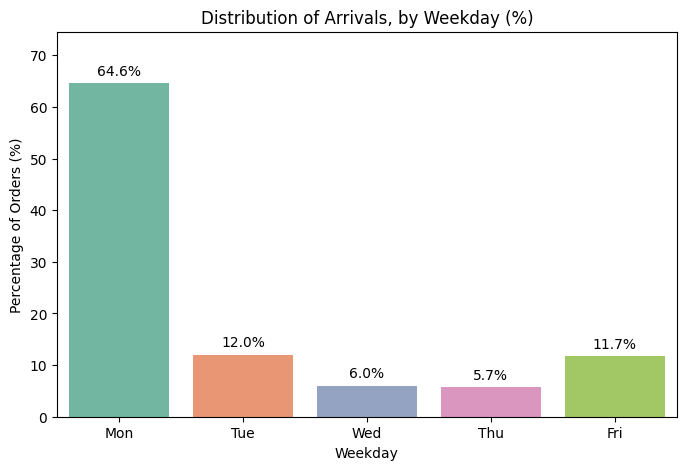

In [42]:
weekday_counts = df_unique_all["arrival_weekday"].value_counts(normalize=True).sort_index()
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Arrivals, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()

#### 4.1.6. The Whole Delivery Process, Distributions of Steps by the Day of the Week
**Conclusions**
* 17% of orders are made on weekends, when no one processes them;
* warehouse definetely doesn't work on the weekends and there are no pickups and no new orders ready to be picked up;
* weird behaviour of trucks: they are not supposed to come for pickups on Tue and Thu;
* 64% of orders arrive to customers on Mondays.

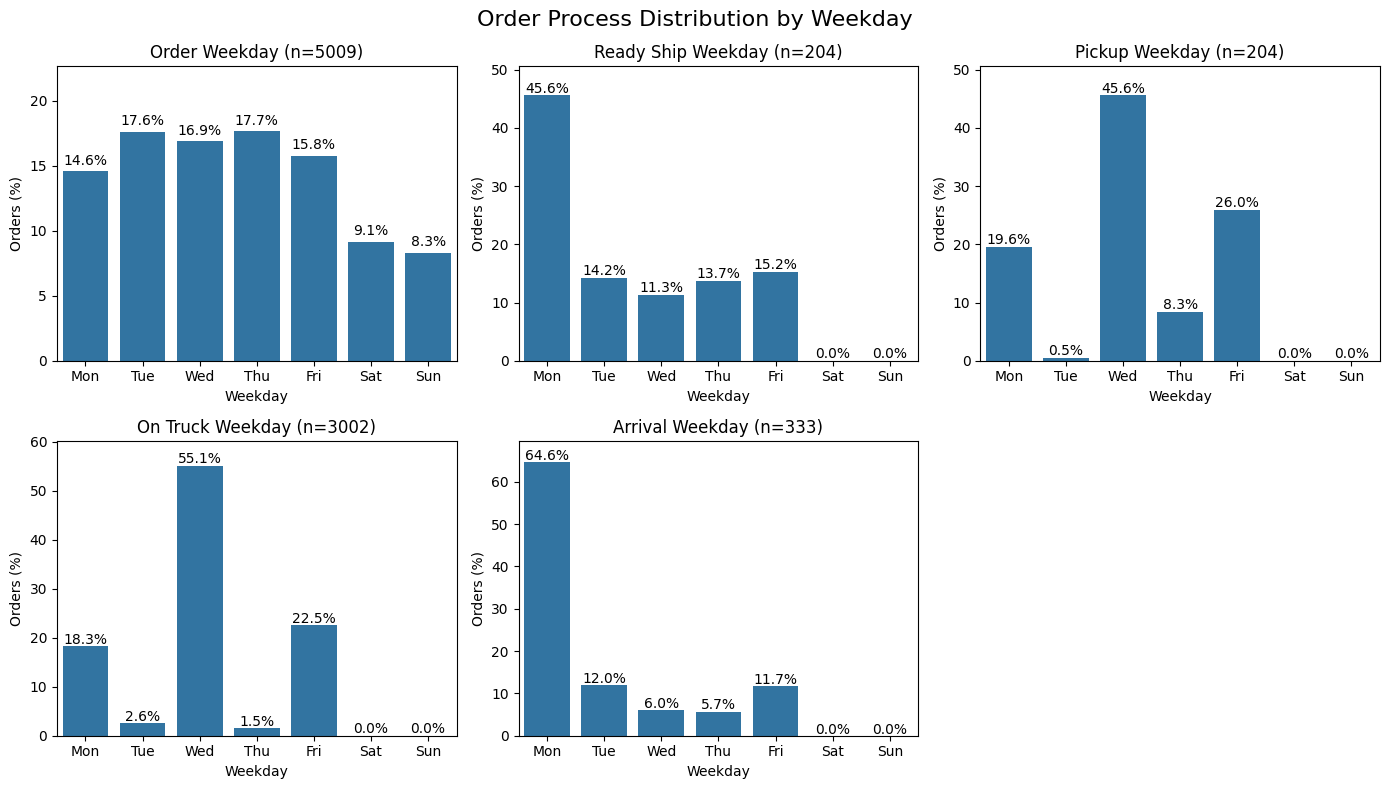

In [43]:
# trying with days names:
weekday_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

# function to define daily distributions:
def weekday_distribution(series):
    counts = (
        series.dropna()
        .value_counts()
        .reindex(range(7), fill_value=0)   # ensures Mon–Sun exist
        .sort_index()
    )
    
    percent = counts / counts.sum() * 100
    percent.index = weekday_labels
    return percent


# the metrics i want:
cols = [
    "order_weekday",
    "ready_ship_weekday",
    "pickup_weekday",
    "on_truck_weekday",
    "arrival_weekday"
]


# the plot
fig, axes = plt.subplots(2, 3, figsize=(14,8))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    
    n = df_unique_all[col].dropna().shape[0]   # sample size
    
    counts = weekday_distribution(df_unique_all[col])
    
    sns.barplot(x=counts.index, y=counts.values, ax=ax)
    
    ax.set_title(f"{col.replace('_',' ').title()} (n={n})")
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Orders (%)")
    
    ax.set_ylim(0, counts.max() + 5)

    # percentage labels
    for i, v in enumerate(counts.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")

# remove empty subplot
fig.delaxes(axes[-1])

plt.suptitle("Order Process Distribution by Weekday", fontsize=16)
plt.tight_layout()
plt.show()

### 4.2. Orders Characteristics
* Number of Items
* Shipment Mode
* Regional Geography

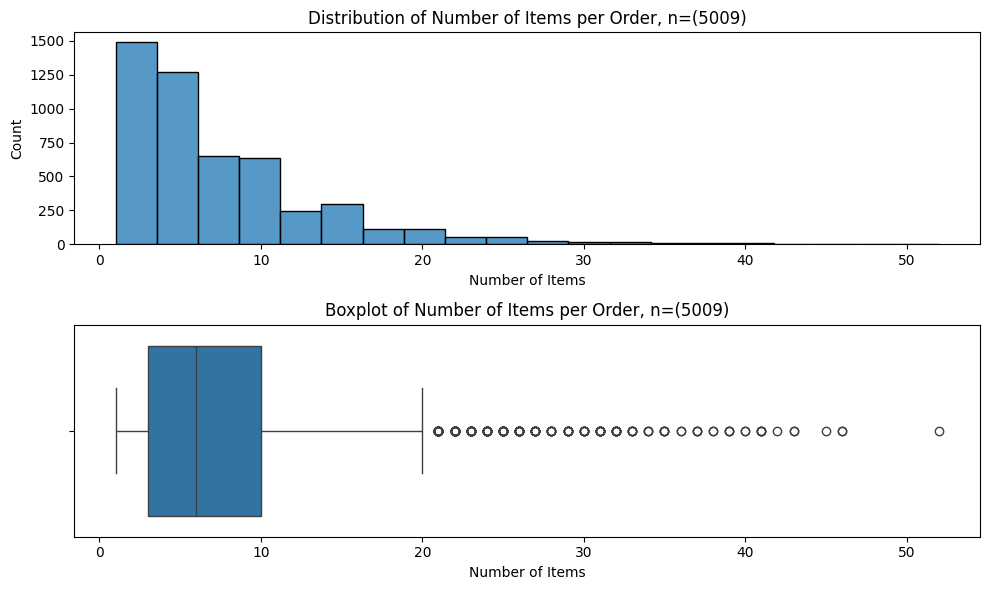

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(10,6))

# histogram
n = len(df_unique_all['total_items'])
sns.histplot(df_unique_all["total_items"], bins=20, ax=axes[0])
axes[0].set_title(f"Distribution of Number of Items per Order, n=({n})")
axes[0].set_xlabel("Number of Items")
axes[0].set_ylabel("Count")

# boxplot
sns.boxplot(x=df_unique_all["total_items"], ax=axes[1])
axes[1].set_title(f"Boxplot of Number of Items per Order, n=({n})")
axes[1].set_xlabel("Number of Items")

plt.tight_layout()
plt.show()

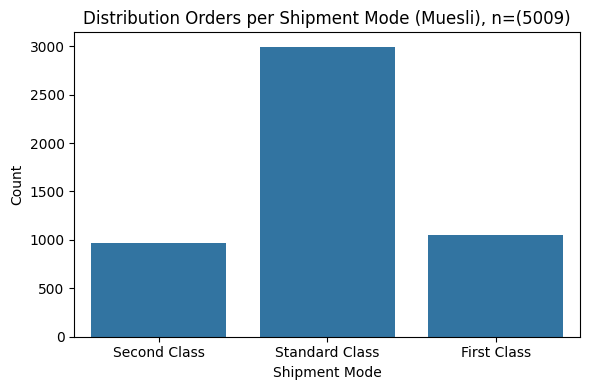

In [45]:
fig, ax = plt.subplots(figsize=(6,4))

# histogram
n = len(df_unique_all['ship_mode'])
sns.countplot(
    data=df_unique_all,
    x="ship_mode",
    ax=ax
)
ax.set_title(f"Distribution Orders per Shipment Mode (Muesli), n=({n})")
ax.set_xlabel("Shipment Mode")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

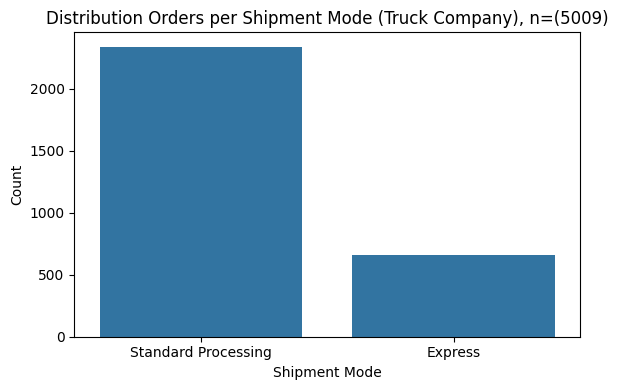

In [46]:
fig, ax = plt.subplots(figsize=(6,4))

# histogram
n = len(df_unique_all['truck_ship_mode'])
sns.countplot(
    data=df_unique_all,
    x="truck_ship_mode",
    ax=ax
)
ax.set_title(f"Distribution Orders per Shipment Mode (Truck Company), n=({n})")
ax.set_xlabel("Shipment Mode")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [47]:
df_unique_all.shape

(5009, 18)

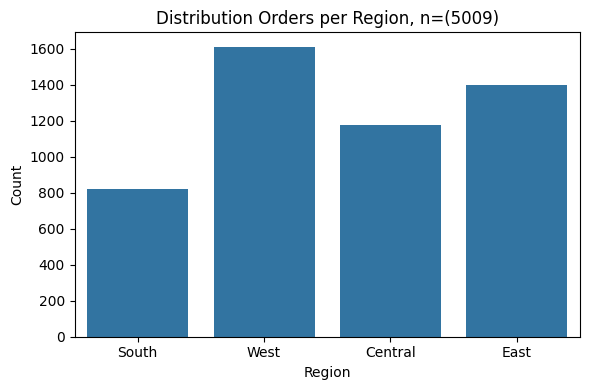

In [48]:
fig, ax = plt.subplots(figsize=(6,4))

# histogram
n = len(df_unique_all['region'])
sns.countplot(
    data=df_unique_all,
    x="region",
    ax=ax
)
ax.set_title(f"Distribution Orders per Region, n=({n})")
ax.set_xlabel("Region")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

### 4.3. Delivery Process Overall Descriptive Statistics (business days)
**Conclusions**
* mean warehouse processing time is **2 business days**;
* mean truck waiting time (days) is **1.35 business days**;
* warehouse data and truck company sata match each other;
* mean transportation (transit) time is **2.9 business days**;
* mean total delivery time is **7.39 business days**.

### 4.3.1. Processing Time (order --> ready to pick up)

In [49]:
df_unique_all['process_days_biz'].describe()

count    204.000000
mean       2.769608
std        1.417991
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        5.000000
Name: process_days_biz, dtype: float64

### 4.3.2. Truck Waiting Days vs. Warehouse Waiting Days
* ready to pickup --> pickup, warehouse data
* ready to pickup --> scan on truck, truck company data

**Conclusion**
Identical metrics --> redundancy.

In [50]:
df_unique_all[['truck_wait_days_biz','war_wait_days_biz']].describe()

,truck_wait_days_biz,war_wait_days_biz
count,204.000000,204.000000
mean,1.357843,1.357843
std,0.821141,0.821141
min,0.000000,0.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,3.000000,3.000000


### 4.3.3. Warehouse Full Data vs. Truck Company Full Data
* order date --> pickup date, warehouse data (small sample)
* order date --> scan on truck, truck company data (bigger sample)

**Conclusion**
The two metrics match each other -> reliable.

In [51]:
df_unique_all[['warehouse_full','truck_data']].describe()

,warehouse_full,truck_data
count,204.000000,3002.000000
mean,4.127451,4.331779
std,1.839209,1.847353
min,0.000000,0.000000
25%,3.000000,3.000000
50%,5.000000,5.000000
75%,5.000000,6.000000
max,7.000000,9.000000


### 4.3.4. Transportation days (scan on truck --> arrival scan)

In [52]:
df_unique_all['transp_days_biz'].describe()

count    333.000000
mean       2.921922
std        0.956855
min        1.000000
25%        3.000000
50%        3.000000
75%        3.000000
max        5.000000
Name: transp_days_biz, dtype: float64

### 4.3.5. Total Delivery Days (order --> arrival scan)

In [53]:
df_unique_all['total_delivery_days_biz'].describe()

count    333.000000
mean       7.399399
std        2.050477
min        1.000000
25%        6.000000
50%        8.000000
75%        9.000000
max       12.000000
Name: total_delivery_days_biz, dtype: float64

## 5. Main KPIs: Calculation and Visualization by Category
For overall KPIs statistics, see above.

### 5.1. By Shipment Mode
There are two columns in the dataset referencing the shipment method.
1. Company categories:
Muesli company has three options of shipment:
* ```'Standard Class'``` = 1772 clients 
* ```'Second Class'```= 568 clients
* ```'First Class'``` = 662 clients

2. Logistic company categories:
But the truck company has it's own logic:
* ```'Express'```= 662 clients
* ```'Standard Processing'```= 2340 clients

This means that truck company treats Second Class and First Class deliveries the same way and puts them into one category. It's not clear why and what does it mean for the clients.

Below all the descriptive statistics (as tables and as boxplots) are avaliable for all shipment modes (both warehouse/Muesli company categories and truck company categories).

In [54]:
df_unique_all.groupby(['ship_mode']).size()

ship_mode
First Class       1051
Second Class       964
Standard Class    2994
dtype: int64

In [55]:
df_unique_all.groupby(['truck_ship_mode']).size()

truck_ship_mode
Express                 662
Standard Processing    2340
dtype: int64

In [56]:
statistics = ["process_days_biz",
    "truck_wait_days_biz",
    "warehouse_full",
    "truck_data",
    "transp_days_biz",
    "total_delivery_days_biz"]

**Conclusions about shipment mode (Muesli), business days**
* first class orders processed in the warehouse on average in 1.3 days; the number is twice higher for dtandard class (3.5 days) and somewhat inbetween for second class (2.6 days);
* the truck waiting time varies significantly for the three categories: 0.4 days for the first class against 1.7 days for the standard class on average;
* full time the order spends in the warehouse is 1.79 days for first class against 5.2 days for the standard class (second class is in between again with 4.2 days); it matches the truck company data;
* transportation takes 2.9 days on average for all categories --> weird;
* total delivery varies from 4.8 for first class to 8.2 for the standard class (with 7.3 days for the second class).

In [57]:
df_unique_all.groupby("ship_mode")[statistics].describe().T

ship_mode                      First Class  Second Class  Standard Class
process_days_biz        count    53.000000     44.000000      107.000000
                        mean      1.396226      2.568182        3.532710
                        std       1.182234      0.974028        1.110140
                        min       0.000000      0.000000        0.000000
                        25%       0.000000      2.000000        3.000000
                        50%       2.000000      3.000000        4.000000
                        75%       2.000000      3.000000        4.000000
                        max       3.000000      5.000000        5.000000
truck_wait_days_biz     count    53.000000     44.000000      107.000000
                        mean      0.396226      1.659091        1.710280
                        std       0.531313      0.568277        0.629605
                        min       0.000000      1.000000        1.000000
                        25%       0.000000      1.000000        1.000000
                        50%       0.000000      2.000000        2.000000
                        75%       1.000000      2.000000        2.000000
                        max       2.000000      3.000000        3.000000
warehouse_full          count    53.000000     44.000000      107.000000
                        mean      1.792453      4.227273        5.242991
                        std       1.276391      1.053535        1.114579
                        min       0.000000      3.000000        2.000000
                        25%       1.000000      3.000000        5.000000
                        50%       2.000000      4.000000        5.000000
                        75%       3.000000      5.000000        6.000000
                        max       4.000000      7.000000        7.000000
truck_data              count   662.000000    568.000000     1772.000000
                        mean      1.853474      4.285211        5.272573
                        std       1.181544      1.154545        1.285665
                        min       0.000000      2.000000        2.000000
                        25%       1.000000      4.000000        5.000000
                        50%       2.000000      4.000000        5.000000
                        75%       3.000000      5.000000        6.000000
                        max       4.000000      9.000000        9.000000
transp_days_biz         count    75.000000     58.000000      200.000000
                        mean      2.853333      2.862069        2.965000
                        std       1.204646      1.033615        0.822898
                        min       1.000000      1.000000        1.000000
                        25%       2.000000      2.000000        3.000000
                        50%       3.000000      3.000000        3.000000
                        75%       3.500000      3.000000        3.000000
                        max       5.000000      5.000000        5.000000
total_delivery_days_biz count    75.000000     58.000000      200.000000
                        mean      4.800000      7.344828        8.390000
                        std       1.515684      1.628170        1.366469
                        min       1.000000      5.000000        4.000000
                        25%       4.000000      6.000000        7.000000
                        50%       5.000000      7.000000        9.000000
                        75%       6.000000      9.000000        9.000000
                        max       9.000000     10.000000       12.000000

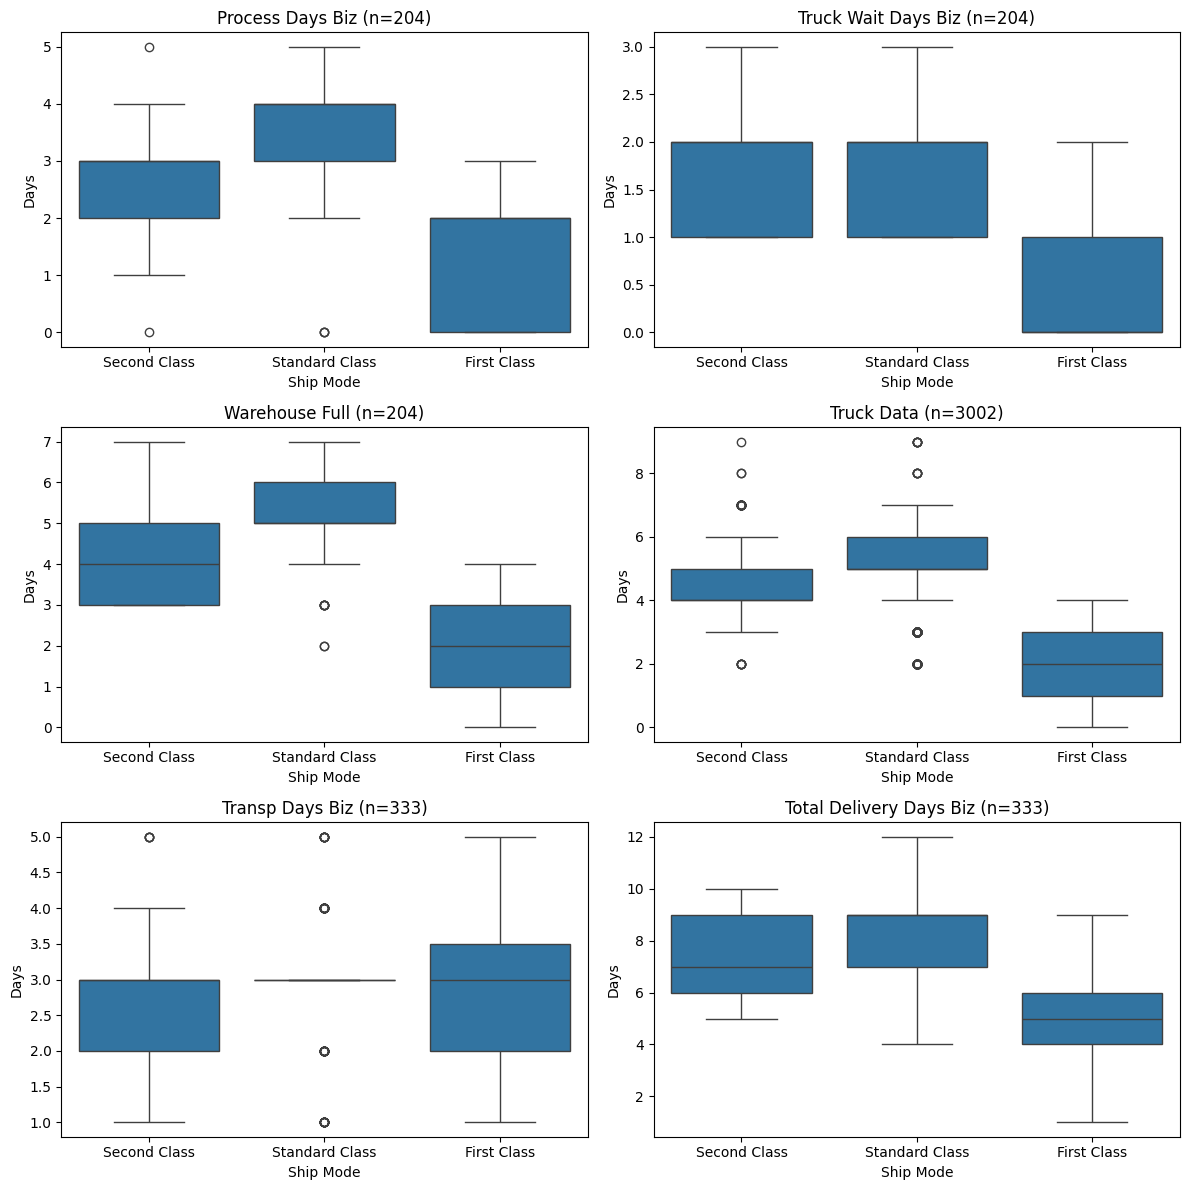

In [58]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), statistics):

    data = df_unique_all.dropna(subset=[metric])
    n = len(data)

    sns.boxplot(data=df_unique_all, x="ship_mode", y=metric, ax=ax)
    ax.set_title(f"{metric.replace('_', ' ').title()} (n={n})")
    ax.set_xlabel("Ship Mode")
    ax.set_ylabel("Days")

plt.tight_layout()
plt.show()

Most of the descriptive statistics calculated on ship_mode (Muesli company categories) match similar statistics, based on two shipment categories from the truck company:

In [59]:
df_unique_all.groupby("truck_ship_mode")[statistics].describe().T

truck_ship_mode                   Express  Standard Processing
process_days_biz        count   53.000000           151.000000
                        mean     1.396226             3.251656
                        std      1.182234             1.155962
                        min      0.000000             0.000000
                        25%      0.000000             2.500000
                        50%      2.000000             3.000000
                        75%      2.000000             4.000000
                        max      3.000000             5.000000
truck_wait_days_biz     count   53.000000           151.000000
                        mean     0.396226             1.695364
                        std      0.531313             0.610938
                        min      0.000000             1.000000
                        25%      0.000000             1.000000
                        50%      0.000000             2.000000
                        75%      1.000000             2.000000
                        max      2.000000             3.000000
warehouse_full          count   53.000000           151.000000
                        mean     1.792453             4.947020
                        std      1.276391             1.187648
                        min      0.000000             2.000000
                        25%      1.000000             4.000000
                        50%      2.000000             5.000000
                        75%      3.000000             6.000000
                        max      4.000000             7.000000
truck_data              count  662.000000          2340.000000
                        mean     1.853474             5.032906
                        std      1.181544             1.324364
                        min      0.000000             2.000000
                        25%      1.000000             4.000000
                        50%      2.000000             5.000000
                        75%      3.000000             6.000000
                        max      4.000000             9.000000
transp_days_biz         count   75.000000           258.000000
                        mean     2.853333             2.941860
                        std      1.204646             0.873581
                        min      1.000000             1.000000
                        25%      2.000000             3.000000
                        50%      3.000000             3.000000
                        75%      3.500000             3.000000
                        max      5.000000             5.000000
total_delivery_days_biz count   75.000000           258.000000
                        mean     4.800000             8.155039
                        std      1.515684             1.491609
                        min      1.000000             4.000000
                        25%      4.000000             7.000000
                        50%      5.000000             8.000000
                        75%      6.000000             9.000000
                        max      9.000000            12.000000

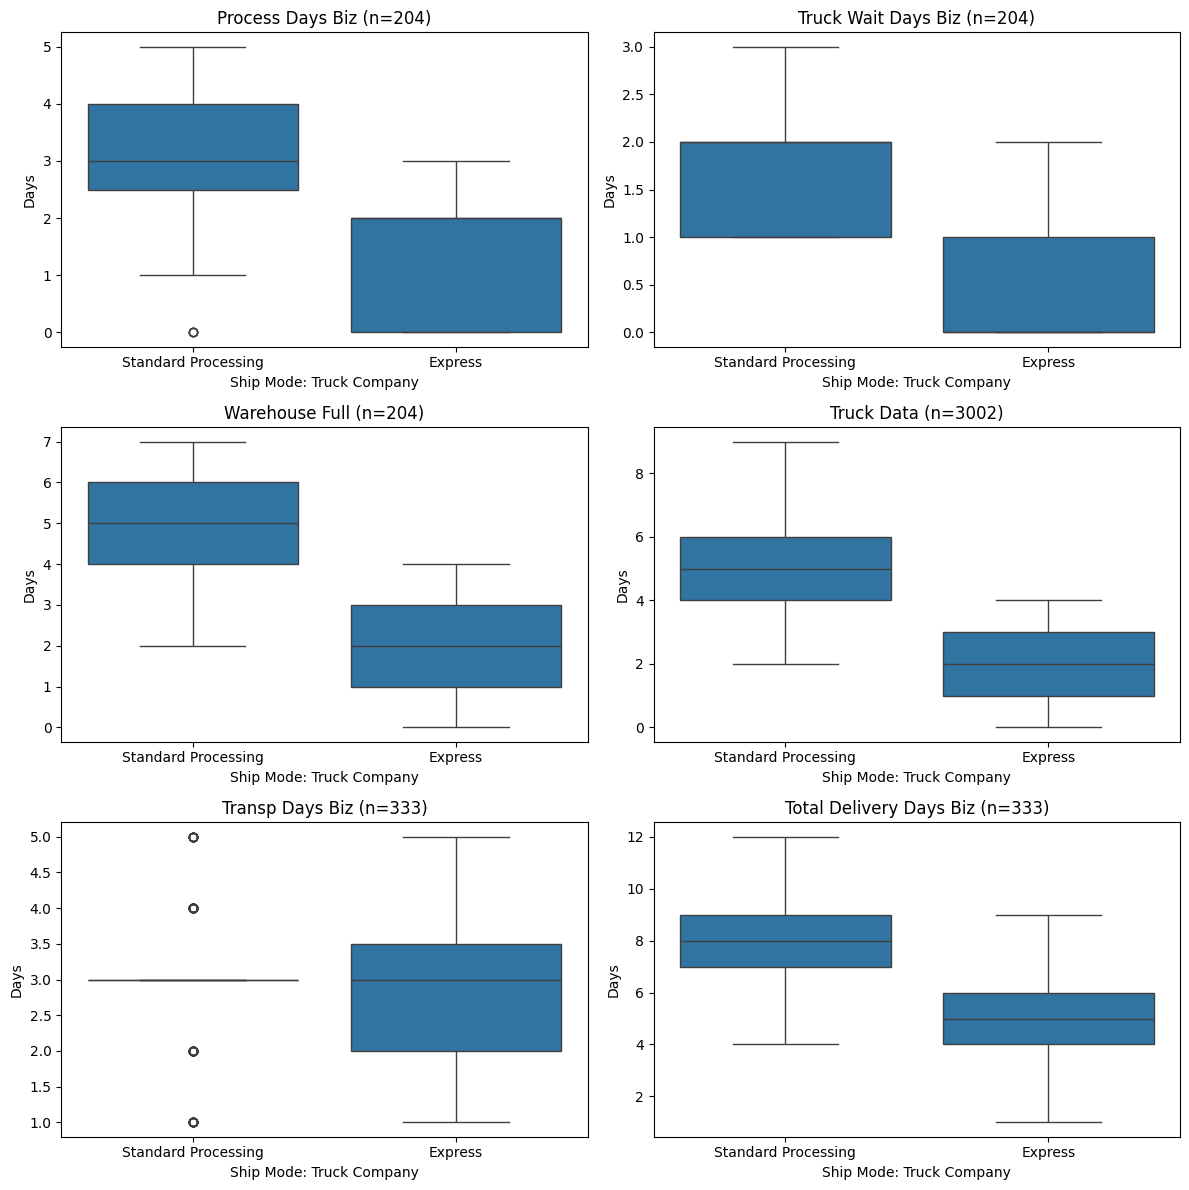

In [60]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), statistics):

    data = df_unique_all.dropna(subset=[metric])
    n= len(data)

    sns.boxplot(data=df_unique_all, x="truck_ship_mode", y=metric, ax=ax)
    ax.set_title(f"{metric.replace('_', ' ').title()} (n={n})")
    ax.set_xlabel("Ship Mode: Truck Company")
    ax.set_ylabel("Days")

plt.tight_layout()
plt.show()

### 5.2. By Region
Region (to where the order is supposed to be delivered) does not play significant role in the processing time (about 2.5-2.9 days), truck waiting days (about 1.2-1.4), full warehouse processing time (~4 days), transportation time (~3 days), or total delivery time (~6-7 days).

In [61]:
df_unique_all.groupby("region")[statistics].describe().T

region                            Central        East       South        West
process_days_biz        count   51.000000   52.000000   41.000000   60.000000
                        mean     2.823529    2.846154    2.975610    2.516667
                        std      1.410048    1.377474    1.214245    1.578367
                        min      0.000000    0.000000    0.000000    0.000000
                        25%      2.000000    2.000000    2.000000    2.000000
                        50%      3.000000    3.000000    3.000000    2.500000
                        75%      4.000000    4.000000    4.000000    4.000000
                        max      5.000000    5.000000    5.000000    5.000000
truck_wait_days_biz     count   51.000000   52.000000   41.000000   60.000000
                        mean     1.176471    1.269231    1.609756    1.416667
                        std      0.841567    0.744006    0.833008    0.829369
                        min      0.000000    0.000000    0.000000    0.000000
                        25%      0.500000    1.000000    1.000000    1.000000
                        50%      1.000000    1.000000    2.000000    1.000000
                        75%      2.000000    2.000000    2.000000    2.000000
                        max      3.000000    3.000000    3.000000    3.000000
warehouse_full          count   51.000000   52.000000   41.000000   60.000000
                        mean     4.000000    4.115385    4.585366    3.933333
                        std      2.039608    1.722445    1.627507    1.885418
                        min      0.000000    0.000000    0.000000    0.000000
                        25%      2.000000    3.000000    3.000000    3.000000
                        50%      5.000000    4.500000    5.000000    4.000000
                        75%      5.500000    5.000000    6.000000    5.000000
                        max      7.000000    7.000000    7.000000    7.000000
truck_data              count  711.000000  844.000000  487.000000  960.000000
                        mean     4.350211    4.351896    4.301848    4.315625
                        std      1.787199    1.851064    1.870624    1.878301
                        min      0.000000    0.000000    0.000000    0.000000
                        25%      3.000000    3.000000    3.000000    3.000000
                        50%      5.000000    5.000000    5.000000    5.000000
                        75%      6.000000    6.000000    6.000000    6.000000
                        max      9.000000    9.000000    8.000000    9.000000
transp_days_biz         count   77.000000   92.000000   49.000000  115.000000
                        mean     2.831169    2.902174    2.897959    3.008696
                        std      0.992108    0.984046    0.984143    0.903168
                        min      1.000000    1.000000    1.000000    1.000000
                        25%      2.000000    3.000000    3.000000    3.000000
                        50%      3.000000    3.000000    3.000000    3.000000
                        75%      3.000000    3.000000    3.000000    3.000000
                        max      5.000000    5.000000    5.000000    5.000000
total_delivery_days_biz count   77.000000   92.000000   49.000000  115.000000
                        mean     6.896104    7.336957    7.632653    7.686957
                        std      2.149568    2.087520    1.787618    2.014706
                        min      1.000000    2.000000    4.000000    3.000000
                        25%      6.000000    6.000000    6.000000    7.000000
                        50%      7.000000    8.000000    8.000000    8.000000
                        75%      9.000000    9.000000    9.000000    9.000000
                        max     11.000000   12.000000   10.000000   11.000000

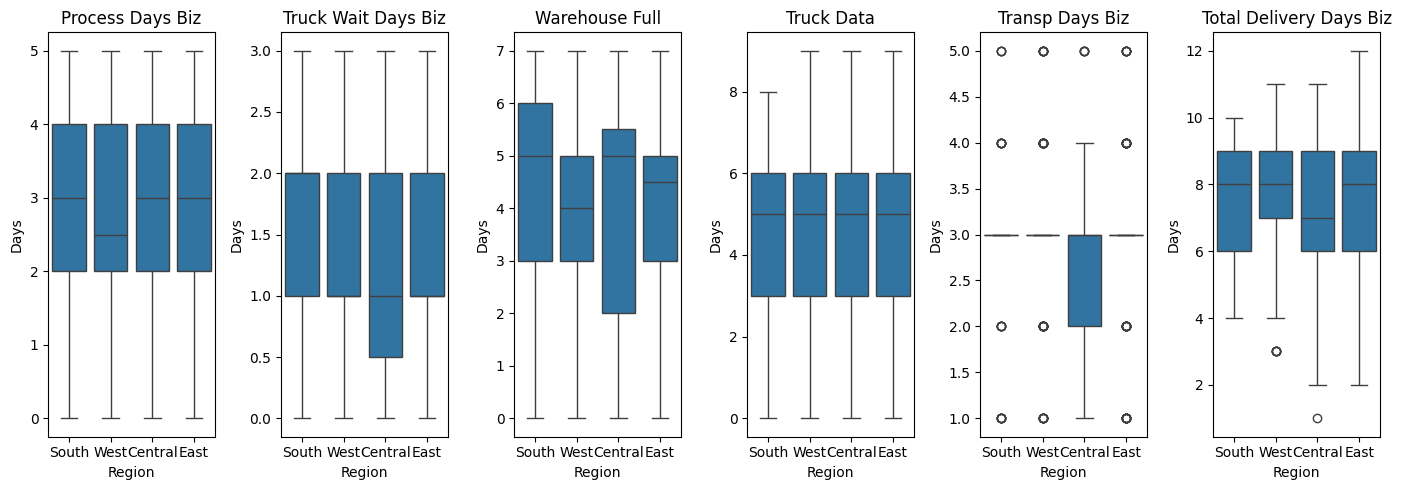

In [62]:
fig, axes = plt.subplots(1, len(statistics), figsize=(14,5))

for ax, col in zip(axes, statistics):
    
    sns.boxplot(
        data=df_unique_all,
        x="region",
        y=col,
        ax=ax
    )
    
    ax.set_title(col.replace("_"," ").title())
    ax.set_xlabel("Region")
    ax.set_ylabel("Days")

plt.tight_layout()
plt.show()

### 5.3. By Number of Orders
First, I checked how many unique total_items values I have in the dataframe. It is 45 different amounts, varying from 1 to 52 items in one order. This it to many to calculate statistics for each amount of items, so I came up with putting them into some "bins".

See more about the process below.

**Conclusions**
The number of items in order does not affect the processing time or other KPIs significantly.

In [63]:
print(f"How many order sizes exist in the dataframe: {len(df_unique_all.groupby('total_items').size())} options of order sizes.")
print(f"Maximum items in one order: {df_unique_all['total_items'].max()}.")
print(f"Minimum items in one order (logically): {df_unique_all['total_items'].min()}")


How many order sizes exist in the dataframe: 46 options of order sizes.
Maximum items in one order: 52.
Minimum items in one order (logically): 1


This is why "normal" bins (aka <10, 10-20,...) won't work:

In [64]:
# what is the distribution of items' amount in the sample:
df_unique_all.groupby('total_items')['total_items'].describe().T

total_items,1,2,3,4,5,6,7,8,9,10,...,37,38,39,40,41,42,43,45,46,52
count,235.0,618.0,636.0,433.0,491.0,346.0,361.0,292.0,255.0,203.0,...,3.0,2.0,3.0,2.0,4.0,1.0,2.0,1.0,2.0,1.0
mean,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,37.0,38.0,39.0,40.0,41.0,42.0,43.0,45.0,46.0,52.0
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,NaN
min,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,37.0,38.0,39.0,40.0,41.0,42.0,43.0,45.0,46.0,52.0
25%,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,37.0,38.0,39.0,40.0,41.0,42.0,43.0,45.0,46.0,52.0
50%,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,37.0,38.0,39.0,40.0,41.0,42.0,43.0,45.0,46.0,52.0
75%,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,37.0,38.0,39.0,40.0,41.0,42.0,43.0,45.0,46.0,52.0
max,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,37.0,38.0,39.0,40.0,41.0,42.0,43.0,45.0,46.0,52.0


In [65]:
# making bins:
bins = [0, 3, 10, 20, 100]
labels = ["1–3", "4–10", "11–20", "20+"]

df_unique_all["items_group"] = pd.cut(
    df_unique_all["total_items"],
    bins=bins,
    labels=labels
)

# Create a new column with the binned groups
df_unique_add["items_group"] = pd.cut(df_unique_all["total_items"],
                                    bins=bins,
                                    labels=labels,
                                    right=False)  # right=False means intervals like [0,10)

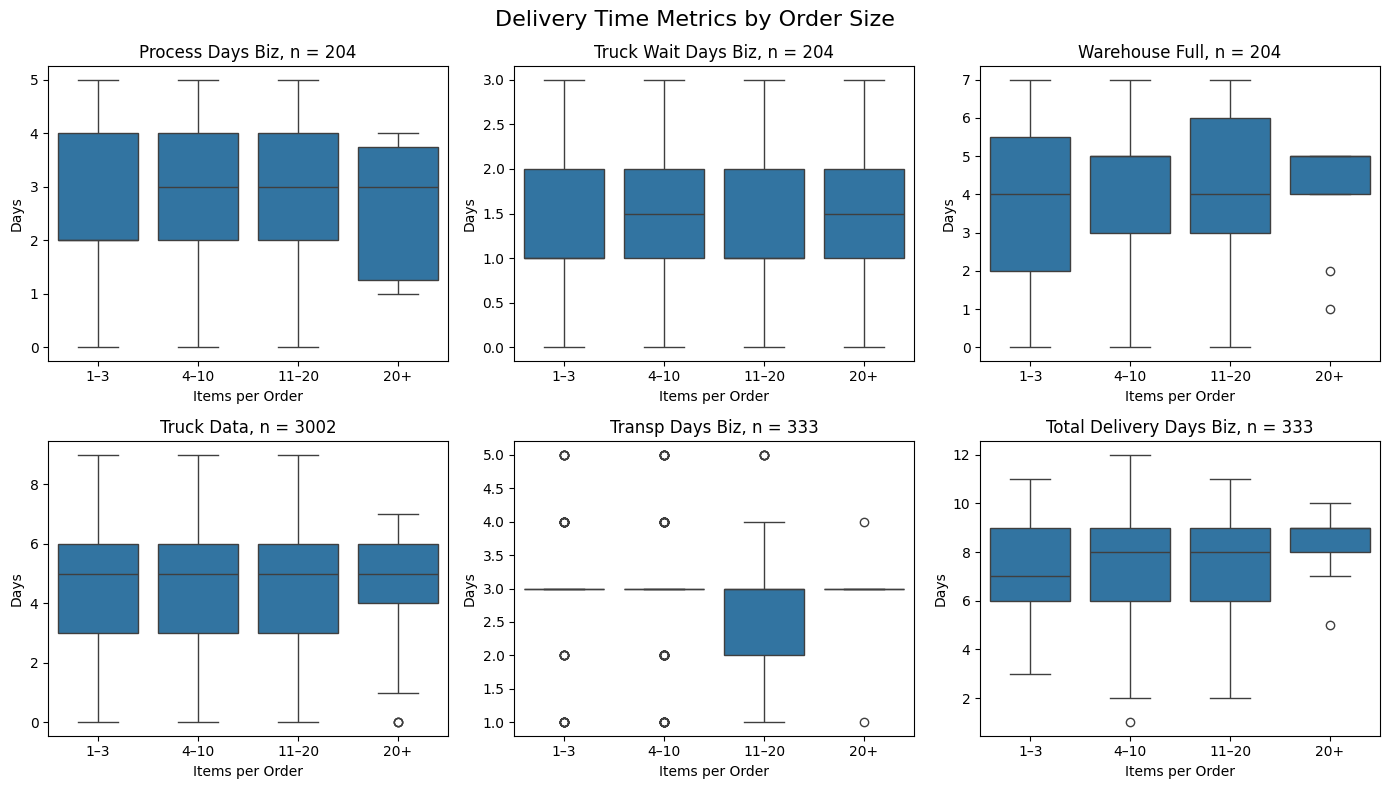

In [66]:
fig, axes = plt.subplots(2, 3, figsize=(14,8))
axes = axes.flatten()


for ax, metric in zip(axes, statistics):
    data = df_unique_all.dropna(subset=[metric])
    n = len(data)

    sns.boxplot(data=df_unique_all, x="items_group", y=metric, ax=ax)
    
    ax.set_title(f"{metric.replace('_', ' ').title()}, n = {n}")
    ax.set_xlabel("Items per Order")
    ax.set_ylabel("Days")


plt.suptitle("Delivery Time Metrics by Order Size", fontsize=16)
plt.tight_layout()
plt.show()

# >>> almost no variation

### 5.4. Delivery Time by When the Order Was Made
**Conclusions**
* Sunday is the most unfortunate day to order something from a Muesli company; orders made on Sunday take the most processing time (in the warehouse) -- probably because of the backlog; Sunday orders also wait loger for the truck pickup; it takes on average 6 business days to process them fully (from order to pickup) in the warehouse;
* but according to the truck data, Mondays are almost as bad as Sundays: the total processing time (order --> scan on truck) takes 5 days (for Sundays also five);
* Monday orders also spend more time on the way (probably, truck drivers also don't work weekends, but we can just assume it);
* total transportation time is higher for Monday orders (8.2 business days).

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/1796606155.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/1796606155.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/1796606155.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/1796606155.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated a

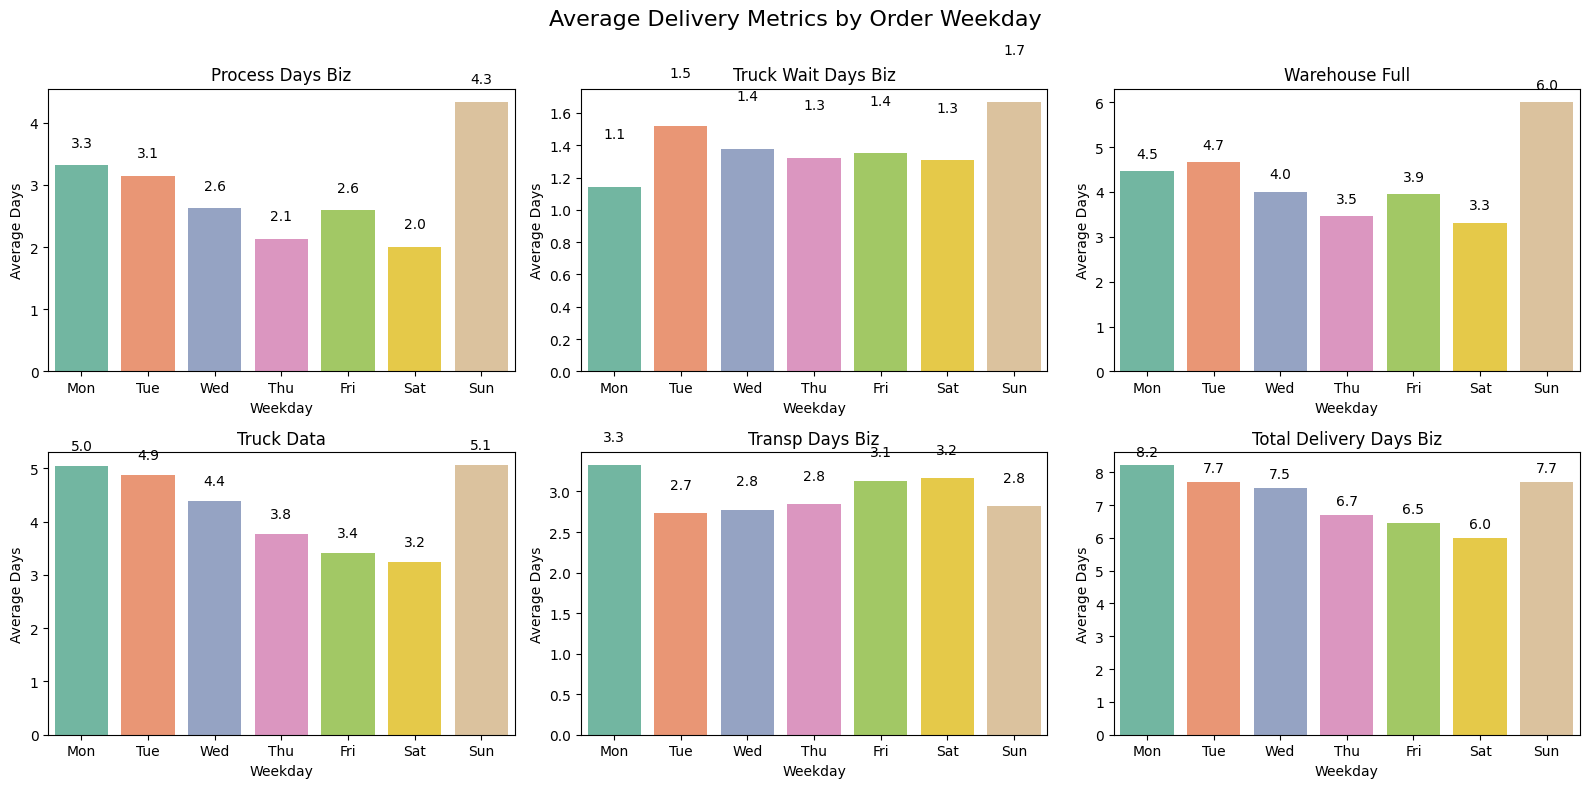

In [67]:
weekday_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig, axes = plt.subplots(2, 3, figsize=(16,8))
axes = axes.flatten()

for ax, col in zip(axes, statistics):

    metric_by_weekday = (
        df_unique_all
        .groupby("order_weekday")[col]
        .mean()
        .sort_index()
    )

    sns.barplot(
        x=weekday_labels,
        y=metric_by_weekday.values,
        ax=ax,
        palette="Set2"
    )

    ax.set_title(col.replace("_"," ").title())
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Average Days")

    # value labels
    for i, val in enumerate(metric_by_weekday.values):
        ax.text(i, val + 0.3, f"{val:.1f}", ha="center")

plt.suptitle("Average Delivery Metrics by Order Weekday", fontsize=16)

plt.tight_layout()
plt.show()

### 5.5. By Origin
There are three option of the order origin:
* email
* facebook
* sales.

The differences between them are nor significant in terms of time (processing, transport, total, etc.)

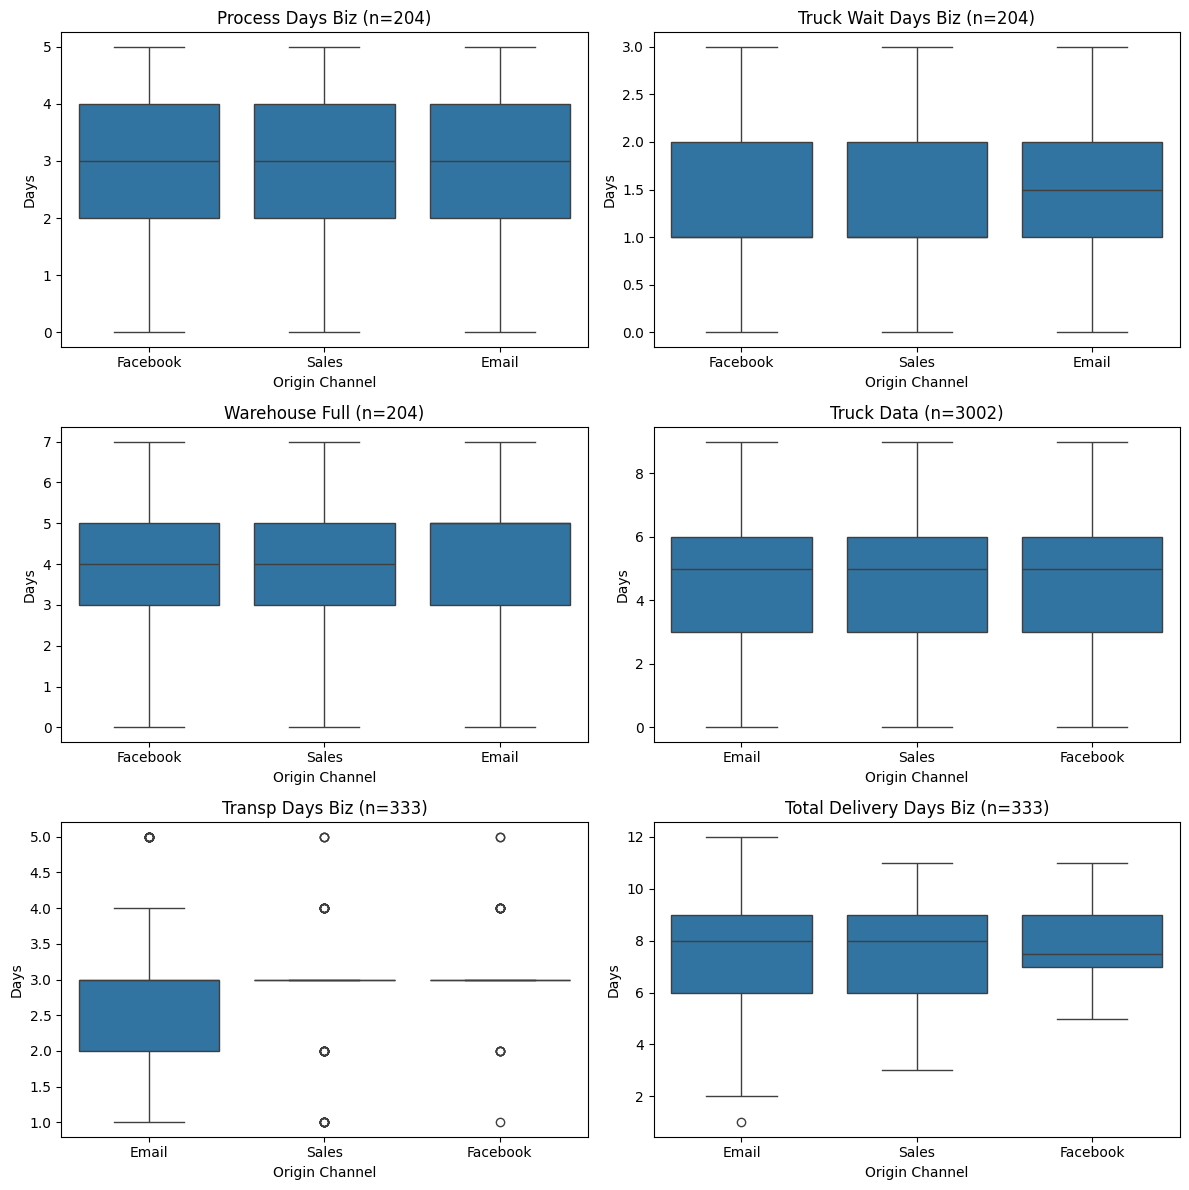

In [68]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()

for ax, metric in zip(axes, statistics):

    # keep only rows where the metric exists
    data = df_unique_all.dropna(subset=[metric])
    n = len(data)

    sns.boxplot(
        data=data,
        x="origin_channel",
        y=metric,
        ax=ax
    )

    ax.set_title(f"{metric.replace('_', ' ').title()} (n={n})")
    ax.set_xlabel("Origin Channel")
    ax.set_ylabel("Days")


plt.tight_layout()

# plt.savefig("2_delivery_by_origin_channel.png", dpi=300, bbox_inches="tight")
plt.show()



### ADDITIONAL: (Truck) Shipment Mode + Day the Order Was Made --> Time
In the following visualization I tried to mix up the delivery mode (express or standard) with the day on which the order was made.
**Conclusions**
* express delivery option makes difference; total delivery time decreases significantly for orders made on any day;
* also truck waiting days have significant difference for the two delivery categories and for all days of ordering;
* somehow express delivery takes more actual transit time that standard processing; I believe that this fact need additional investigation.

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/3590137888.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(weekday_labels)
/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/3590137888.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(weekday_labels)
/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/3590137888.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(weekday_labels)
/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_55955/3590137888.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(weekday_labels)
/var/fol

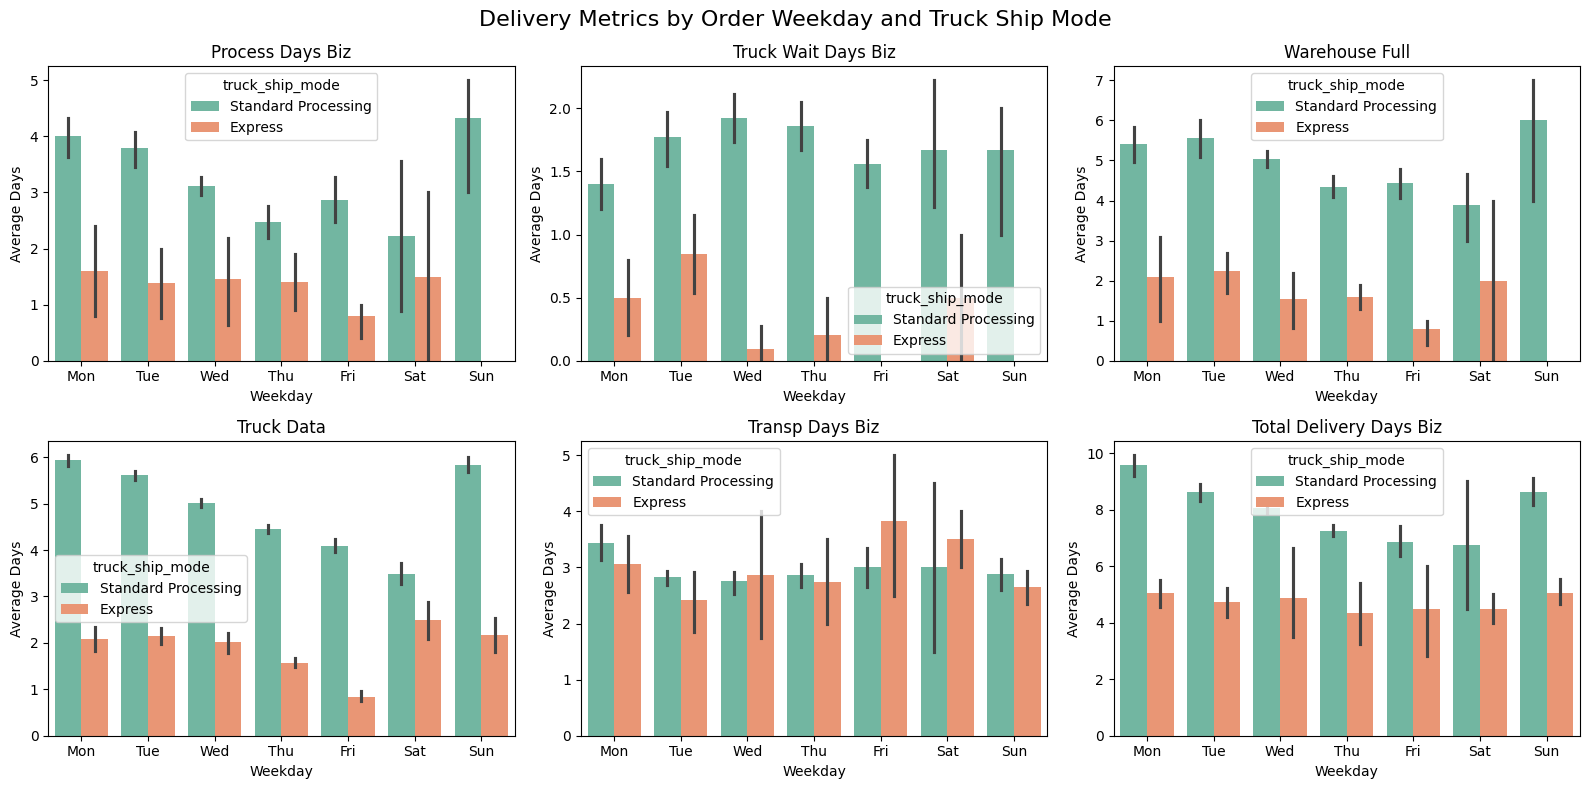

In [69]:
weekday_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig, axes = plt.subplots(2, 3, figsize=(16,8))
axes = axes.flatten()

for ax, col in zip(axes, statistics):

    sns.barplot(
        data=df_unique_all,
        x="order_weekday",
        y=col,
        hue="truck_ship_mode",
        estimator="mean",
        ax=ax,
        palette="Set2"
    )

    ax.set_xticklabels(weekday_labels)
    ax.set_title(col.replace("_"," ").title())
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Average Days")

plt.suptitle("Delivery Metrics by Order Weekday and Truck Ship Mode", fontsize=16)

plt.tight_layout()
plt.show()

## Conclusions and Recommendations

Some conclusions previously mentioned in the notebook:
* orders are still placed during weekends -> a backlog that must be processed on Monday; Monday has higher processing pressure;
* total delivery time is dominated by pre-transport stage --> warehouse;
* truck schedule creates some additional waiting time;
* transport time is pretty stable across different categories of orders;
* limited data --> limited analysis;
* express shipment really resuces time.

**Manager's Assumptions vs. EDA**
| Metrics | Company's Assumption | EDA Estimation | Match/Mismatch |
|----------|----------|----------|----------|
| Warehouse Processing Time  | 2 days | 2.76 days | Almost |
| Waiting for a Truck | 1 day | 1.35 days  | Yes |
| Full warehouse Time | 3-4 days | 4 days | Yes | 
| Transportation (Transit) Time | 3 days | 2.9 days | Yes | 
| Total Delivery Time | 9-10 days | 7.39 days | Even better* | 

*But heavily depends on shipment mode!

**Recommendations**
* improving the data quality: one of the recommendations could be a better approach to data collection and optimization of each stage status; it's useful not only for the business but for increased customers satisfaction;
* improving the work of the warehouse since the warehouse processing time is much slower than the company estimation;
* improving the shipment method categorization (first class aka express and second class/ standard class aka standard processing).